# Producing the inputs for the decay-angle study

`mulj_decay_angle.ipynb` next to this file reads one merged `.coffea` per sample.  This
notebook is where those come from.

It has two halves.  The first runs here, on two files of one signal sample and two of one
data sample, and its outputs are committed: they are the evidence that the recipe below
works, not a physics result.  The second half is the full campaign, 193,770 files over 152
samples, which does not run in a notebook; section 2 shows how to run it and points to the
README for the exact commands that produced the inputs the study uses.

Nothing here is specific to one working copy: the sample lists, the submit files and the
job-argument generator are all in the repository.

In [1]:
import os
import sys

from coffea import processor
import coffea.util

# the repository root, whether the notebook was started here or from the root
_repo = os.getcwd().split("/sidm")[0]
if _repo not in sys.path:
    sys.path.insert(1, _repo)

from sidm.tools import llpnanoaodschema, sidm_processor, utilities

utilities.set_plot_style()
%matplotlib inline

print("repository root:", _repo)
print("sidm imported from:", os.path.dirname(os.path.dirname(sidm_processor.__file__)))

repository root: /uscms_data/d3/murtazas/SIDM-wt-decayangle
sidm imported from: /uscms_data/d3/murtazas/SIDM-wt-decayangle/sidm


## Configuration

The channels and histogram collections below are the ones the campaign ran, copied from
`condor/submit_mulj_*.sub`.  Data is processed in the five regions the study compares;
simulation adds the two signal channels, their signal-region variants and their variants
without the muon momentum cut, which are kept for cross-checks.

The channels are defined in `configs/selections_mulj_decay_angle_as_run.yaml`, the definitions
the campaign ran with, frozen when the analysis-wide `configs/selections.yaml` later changed
channels of the same names.  Both processors below are given that file explicitly; leaving it
out would select different events under the same channel names.

Two histogram collections are filled.  `mulj_decay_angle` holds everything the study draws;
`mulj_decay_angle_gen` holds the generator-level angle and is filled for simulation only,
since there is nothing to fill it from in data.

The campaign ran with **unweighted histograms**: no cross-section or generator weight is
applied at fill time.  The study normalises to unit area and applies the luminosity times
cross-section factor itself where it needs one, so do not change this without reading
caveat 5 of `README.md`.

In [2]:
# regions the study compares; data is processed in these five
CH_DATA = [
    "data_control_region_1muLj",
    "data_control_region_1muLj_cosmic_veto",
    "data_control_region_1muLj_spread_cosAlpha_mu_veto",
    "test_VR_2mu2e_invDisplaced_spread_cosAlpha_mu_veto",
    "test_VR_4mu_invDisplaced_spread_cosAlpha_mu_veto",
]

# simulation adds the signal channels and their variants
CH_MC = CH_DATA + [
    "4mu", "2mu2e",
    "4mu_sr", "2mu2e_sr",
    "4mu_noMuPtCut", "2mu2e_noMuPtCut",
]

# the channel definitions the campaign ran with, relative to sidm/
SELECTIONS_CFG = "configs/selections_mulj_decay_angle_as_run.yaml"

COLLECTIONS_MC = ["mulj_decay_angle", "mulj_decay_angle_gen"]
COLLECTIONS_DATA = ["mulj_decay_angle"]

NTUPLE_VERSION = "llpNanoAOD_v2"
UNWEIGHTED_HIST = True

# one location config per category, as the submit files pass them
LOCATION_CFG = {
    "signal_4mu": "signal_4mu_v10.yaml",
    "signal_2mu2e": "signal_2mu2e_v10.yaml",
    "background": "backgrounds.yaml",
    "data": "data_skimmed.yaml",
}

print(f"{len(CH_DATA)} data channels, {len(CH_MC)} simulation channels")

5 data channels, 11 simulation channels


In [3]:
def read_sample_list(name):
    """The committed sample list of one campaign category."""
    path = os.path.join(_repo, "condor", f"mulj_{name}_samples.txt")
    with open(path, encoding="utf-8") as handle:
        return [line.strip() for line in handle
                if line.strip() and not line.startswith("#")]


SAMPLES = {name: read_sample_list(name) for name in
           ("signal_4mu", "signal_2mu2e", "background", "data")}

for name, samples in SAMPLES.items():
    print(f"{name:<13} {len(samples):>3} samples   e.g. {samples[0]}")
print(f"{'total':<13} {sum(len(s) for s in SAMPLES.values()):>3} samples")

signal_4mu     33 samples   e.g. 4Mu_100GeV_0p25GeV_0p02mm
signal_2mu2e   33 samples   e.g. 2Mu2E_100GeV_0p25GeV_0p02mm
background     18 samples   e.g. DYJetsToLL_M10to50
data           68 samples   e.g. DoubleMuon_2018A_0
total         152 samples


## 1. A run that fits in a notebook

Two files of one signal sample and two of one data sample, processed here with coffea's
iterative executor.  This is the same processor, the same channels and the same collections
the campaign uses; only the number of files differs.

`replace_xcache=True` is required on the LPC.  The location configs address files as
`root://xcache//...`, which resolves on coffea-casa and nowhere else; the flag rewrites
them to `root://cmseos.fnal.gov//...`.

The two cells below print a wall of warnings, one per chunk, and all of them are expected.
`Unable to apply ... for nested dsaMuons collection` is a cut that does not apply to
displaced-standalone muons; the `genMus`, `genEs`, `genAs` and `cannot fill counter` lines
are the generator-level collections, absent from data by definition; `Signal not in xs cfg,
assuming 1fb` is the missing cross section for this signal point, which does not matter
here because the histograms are unweighted and the study normalises to unit area anyway.
The other processing notebooks in this repository print the same set.

In [4]:
SIGNAL_SAMPLE = "4Mu_500GeV_1p2GeV_1p9mm"
DATA_SAMPLE = "DoubleMuon_2018A_0"
MAX_FILES = 2

runner = processor.Runner(
    # status=False: the progress widget does not survive into a saved notebook
    executor=processor.IterativeExecutor(status=False),
    schema=llpnanoaodschema.LLPNanoAODSchema,
    chunksize=50_000,
    skipbadfiles=True,
)

print("signal:", SIGNAL_SAMPLE, "  data:", DATA_SAMPLE, f"  {MAX_FILES} files each")

signal: 4Mu_500GeV_1p2GeV_1p9mm   data: DoubleMuon_2018A_0   2 files each


In [5]:
fileset_signal = utilities.make_fileset(
    [SIGNAL_SAMPLE], NTUPLE_VERSION, max_files=MAX_FILES,
    location_cfg=LOCATION_CFG["signal_4mu"], replace_xcache=True)

processor_mc = sidm_processor.SidmProcessor(
    CH_MC, COLLECTIONS_MC, unweighted_hist=UNWEIGHTED_HIST, selections_cfg=SELECTIONS_CFG)

output_signal = runner.run(fileset_signal, treename="Events",
                           processor_instance=processor_mc)
print("signal done")

Ignoring signal cross sections, assuming 1 fb
signal done


In [6]:
fileset_data = utilities.make_fileset(
    [DATA_SAMPLE], NTUPLE_VERSION, max_files=MAX_FILES,
    location_cfg=LOCATION_CFG["data"], replace_xcache=True)

processor_data = sidm_processor.SidmProcessor(
    CH_DATA, COLLECTIONS_DATA, unweighted_hist=UNWEIGHTED_HIST, selections_cfg=SELECTIONS_CFG)

output_data = runner.run(fileset_data, treename="Events",
                         processor_instance=processor_data)
print("data done")

DoubleMuon_2018A_0 is data. Not scaling histograms or cutflows.
data done


### Saving

One file per sample, named after the sample, which is what the merge step produces at full
scale and what the study's `INPUT_DIR` expects.  Here they go to a scratch directory rather
than into the repository.

In [7]:
OUT_DIR = os.path.join(os.path.expanduser("~"), "mulj_demo_outputs")
os.makedirs(OUT_DIR, exist_ok=True)

for sample, output in ((SIGNAL_SAMPLE, output_signal), (DATA_SAMPLE, output_data)):
    path = os.path.join(OUT_DIR, f"{sample}.coffea")
    coffea.util.save(output["out"][sample], path)
    print(f"wrote {path}  ({os.path.getsize(path) / 1e3:.0f} kB)")

wrote /uscms/home/murtazas/mulj_demo_outputs/4Mu_500GeV_1p2GeV_1p9mm.coffea  (156 kB)
wrote /uscms/home/murtazas/mulj_demo_outputs/DoubleMuon_2018A_0.coffea  (35 kB)


### One histogram, as a sanity check

The decay angle of the signal sample in its own channel.  Two files is far too little for
physics; the point is that the axis exists, is filled, and covers zero to one.

8366 muon-lepton-jet pairs in the 4mu channel of 2 files


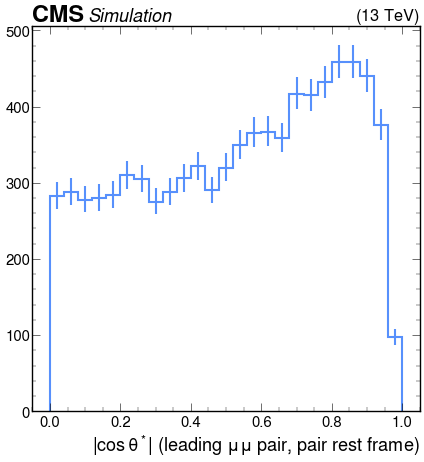

In [8]:
histogram = output_signal["out"][SIGNAL_SAMPLE]["hists"]["mu_lj_mumu_absCosTheta"]
utilities.plot(histogram["4mu", :], flow="none", yerr=True, density=False, linewidth=3)

entries = histogram["4mu", :].values().sum()
print(f"{entries:.0f} muon-lepton-jet pairs in the 4mu channel of {MAX_FILES} files")

## 2. The full campaign

Neither route below runs in this notebook: the code blocks are shown as commands to copy,
not as cells.  The campaign the study uses was produced by the second route.

### Route (a): Dask, from a notebook

Good for one category or a re-run of a handful of samples.  `scaleout.make_lpc_client`
starts an `lpcjobqueue` cluster and ships the working copy to the workers.  Watch the
memory of the notebook kernel itself, not only the workers.

```python
from sidm.tools import scaleout

client = scaleout.make_lpc_client(min_workers=10, max_workers=100, memory="4GB")

runner = processor.Runner(
    executor=processor.DaskExecutor(client=client),
    schema=llpnanoaodschema.LLPNanoAODSchema,
    chunksize=50_000,
    skipbadfiles=True,
)

fileset = utilities.make_fileset(
    SAMPLES["signal_4mu"], NTUPLE_VERSION, max_files=-1,
    location_cfg=LOCATION_CFG["signal_4mu"], replace_xcache=True)

output = runner.run(fileset, treename="Events", processor_instance=processor_mc)
coffea.util.save(output["out"], "signal_4mu.coffea")
```

### Route (b): Condor, which is what produced the study's inputs

The commands are in this directory's `README.md`, under "Reproducing the inputs": step 1
generates the file lists and job arguments and submits one cluster per category, step 2
merges the chunks into one `.coffea` per sample, and step 3 points `mulj_decay_angle.ipynb`
at the merged directory.  The channel lists, the collections and the selections file of the
configuration cell above are baked into the submit files, so they do not have to be passed
again.